In [2]:
from google.colab import files
import pandas as pd

uploaded = files.upload()

filename = next(iter(uploaded))
df = pd.read_csv(filename)

print("Dataset shape:", df.shape)
print("Columns:", df.columns.tolist())

display(df.head())

Saving mtsamples.csv to mtsamples.csv
Dataset shape: (4999, 6)
Columns: ['Unnamed: 0', 'description', 'medical_specialty', 'sample_name', 'transcription', 'keywords']


,Unnamed: 0,description,medical_specialty,sample_name,transcription,keywords
0,0,A 23-year-old white female presents with comp...,Allergy / Immunology,Allergic Rhinitis,"SUBJECTIVE:, This 23-year-old white female pr...","allergy / immunology, allergic rhinitis, aller..."
1,1,Consult for laparoscopic gastric bypass.,Bariatrics,Laparoscopic Gastric Bypass Consult - 2,"PAST MEDICAL HISTORY:, He has difficulty climb...","bariatrics, laparoscopic gastric bypass, weigh..."
2,2,Consult for laparoscopic gastric bypass.,Bariatrics,Laparoscopic Gastric Bypass Consult - 1,"HISTORY OF PRESENT ILLNESS: , I have seen ABC ...","bariatrics, laparoscopic gastric bypass, heart..."
3,3,2-D M-Mode. Doppler.,Cardiovascular / Pulmonary,2-D Echocardiogram - 1,"2-D M-MODE: , ,1. Left atrial enlargement wit...","cardiovascular / pulmonary, 2-d m-mode, dopple..."
4,4,2-D Echocardiogram,Cardiovascular / Pulmonary,2-D Echocardiogram - 2,1. The left ventricular cavity size and wall ...,"cardiovascular / pulmonary, 2-d, doppler, echo..."


In [3]:
print(df["medical_specialty"].value_counts())

medical_specialty
Surgery                          1103
Consult - History and Phy.        516
Cardiovascular / Pulmonary        372
Orthopedic                        355
Radiology                         273
General Medicine                  259
Gastroenterology                  230
Neurology                         223
SOAP / Chart / Progress Notes     166
Obstetrics / Gynecology           160
Urology                           158
Discharge Summary                 108
ENT - Otolaryngology               98
Neurosurgery                       94
Hematology - Oncology              90
Ophthalmology                      83
Nephrology                         81
Emergency Room Reports             75
Pediatrics - Neonatal              70
Pain Management                    62
Psychiatry / Psychology            53
Office Notes                       51
Podiatry                           47
Dermatology                        29
Dentistry                          27
Cosmetic / Plastic Surgery      

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import time

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer

from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import LinearSVC
from sklearn.naive_bayes import MultinomialNB

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

print("Libraries imported successfully!")

Libraries imported successfully!


In [5]:
X = df["transcription"]
y = df["medical_specialty"]

# Remove classes with fewer than 2 samples if any exist
counts = y.value_counts()
valid_classes = counts[counts >= 2].index

df = df[df["medical_specialty"].isin(valid_classes)].copy()

X = df["transcription"]
y = df["medical_specialty"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 3999
Testing samples: 1000


In [6]:
print(df.columns.tolist())
print(df.head())

['Unnamed: 0', 'description', 'medical_specialty', 'sample_name', 'transcription', 'keywords']
   Unnamed: 0                                        description  \
0           0   A 23-year-old white female presents with comp...   
1           1           Consult for laparoscopic gastric bypass.   
2           2           Consult for laparoscopic gastric bypass.   
3           3                             2-D M-Mode. Doppler.     
4           4                                 2-D Echocardiogram   

             medical_specialty                                sample_name  \
0         Allergy / Immunology                         Allergic Rhinitis    
1                   Bariatrics   Laparoscopic Gastric Bypass Consult - 2    
2                   Bariatrics   Laparoscopic Gastric Bypass Consult - 1    
3   Cardiovascular / Pulmonary                    2-D Echocardiogram - 1    
4   Cardiovascular / Pulmonary                    2-D Echocardiogram - 2    

                                 

In [7]:
# Remove rows with missing text or category
df = df.dropna(
    subset=["transcription", "medical_specialty"]
).copy()

# Ensure the columns contain strings
df["transcription"] = df["transcription"].astype(str)
df["medical_specialty"] = df["medical_specialty"].astype(str)

# Define input text and target labels
X = df["transcription"]
y = df["medical_specialty"]

# Split the dataset
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 3972
Testing samples: 994


In [8]:
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer(
    lowercase=True,
    stop_words="english",
    max_features=10000,
    ngram_range=(1, 2),
    sublinear_tf=True
)

X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)

print("Training feature shape:", X_train_tfidf.shape)
print("Testing feature shape:", X_test_tfidf.shape)

Training feature shape: (3972, 10000)
Testing feature shape: (994, 10000)


In [9]:
dt_model = DecisionTreeClassifier(
    random_state=42,
    max_depth=100,
    class_weight="balanced"
)

dt_model.fit(X_train_tfidf, y_train)

dt_pred = dt_model.predict(X_test_tfidf)

print("DECISION TREE RESULTS")
print("Accuracy:", accuracy_score(y_test, dt_pred))
print(classification_report(
    y_test, dt_pred, zero_division=0
))

DECISION TREE RESULTS
Accuracy: 0.06941649899396378
                                precision    recall  f1-score   support

          Allergy / Immunology       0.00      0.00      0.00         2
                       Autopsy       0.00      0.00      0.00         1
                    Bariatrics       0.00      0.00      0.00         2
    Cardiovascular / Pulmonary       0.15      0.19      0.17        79
                  Chiropractic       0.00      0.00      0.00         2
    Consult - History and Phy.       0.02      0.01      0.01       111
    Cosmetic / Plastic Surgery       0.00      0.00      0.00         7
                     Dentistry       0.14      0.12      0.13         8
                   Dermatology       0.00      0.00      0.00         2
          Diets and Nutritions       0.00      0.00      0.00         1
             Discharge Summary       0.08      0.04      0.06        23
          ENT - Otolaryngology       0.13      0.06      0.09        32
        Eme

In [10]:
knn_model = KNeighborsClassifier(
    n_neighbors=5,
    metric="cosine",
    algorithm="brute"
)

knn_model.fit(X_train_tfidf, y_train)

knn_pred = knn_model.predict(X_test_tfidf)

print("KNN RESULTS")
print("Accuracy:", accuracy_score(y_test, knn_pred))
print(classification_report(
    y_test, knn_pred, zero_division=0
))

KNN RESULTS
Accuracy: 0.21227364185110664
                                precision    recall  f1-score   support

          Allergy / Immunology       0.00      0.00      0.00         2
                       Autopsy       1.00      1.00      1.00         1
                    Bariatrics       0.00      0.00      0.00         2
    Cardiovascular / Pulmonary       0.27      0.38      0.31        79
                  Chiropractic       0.00      0.00      0.00         2
    Consult - History and Phy.       0.24      0.33      0.28       111
    Cosmetic / Plastic Surgery       0.00      0.00      0.00         7
                     Dentistry       0.20      0.12      0.15         8
                   Dermatology       0.00      0.00      0.00         2
          Diets and Nutritions       0.00      0.00      0.00         1
             Discharge Summary       0.36      0.22      0.27        23
          ENT - Otolaryngology       0.33      0.16      0.21        32
        Emergency Roo

In [11]:
svm_model = LinearSVC(
    random_state=42,
    class_weight="balanced",
    max_iter=5000
)

svm_model.fit(X_train_tfidf, y_train)

svm_pred = svm_model.predict(X_test_tfidf)

print("SVM RESULTS")
print("Accuracy:", accuracy_score(y_test, svm_pred))
print(classification_report(
    y_test, svm_pred, zero_division=0
))

SVM RESULTS
Accuracy: 0.12474849094567404
                                precision    recall  f1-score   support

          Allergy / Immunology       0.00      0.00      0.00         2
                       Autopsy       1.00      1.00      1.00         1
                    Bariatrics       0.00      0.00      0.00         2
    Cardiovascular / Pulmonary       0.20      0.24      0.22        79
                  Chiropractic       0.00      0.00      0.00         2
    Consult - History and Phy.       0.07      0.05      0.05       111
    Cosmetic / Plastic Surgery       0.00      0.00      0.00         7
                     Dentistry       0.42      0.62      0.50         8
                   Dermatology       0.10      0.50      0.17         2
          Diets and Nutritions       0.00      0.00      0.00         1
             Discharge Summary       0.20      0.13      0.16        23
          ENT - Otolaryngology       0.26      0.16      0.20        32
        Emergency Roo

In [12]:
nb_model = MultinomialNB()

nb_model.fit(X_train_tfidf, y_train)

nb_pred = nb_model.predict(X_test_tfidf)

print("NAIVE BAYES RESULTS")
print("Accuracy:", accuracy_score(y_test, nb_pred))
print(classification_report(
    y_test, nb_pred, zero_division=0
))

NAIVE BAYES RESULTS
Accuracy: 0.3772635814889336
                                precision    recall  f1-score   support

          Allergy / Immunology       0.00      0.00      0.00         2
                       Autopsy       0.00      0.00      0.00         1
                    Bariatrics       0.00      0.00      0.00         2
    Cardiovascular / Pulmonary       0.43      0.30      0.36        79
                  Chiropractic       0.00      0.00      0.00         2
    Consult - History and Phy.       0.30      0.97      0.45       111
    Cosmetic / Plastic Surgery       0.00      0.00      0.00         7
                     Dentistry       0.00      0.00      0.00         8
                   Dermatology       0.00      0.00      0.00         2
          Diets and Nutritions       0.00      0.00      0.00         1
             Discharge Summary       0.00      0.00      0.00        23
          ENT - Otolaryngology       0.00      0.00      0.00        32
        Emerge

In [13]:
models_predictions = {
    "Decision Tree": dt_pred,
    "KNN": knn_pred,
    "SVM": svm_pred,
    "Naive Bayes": nb_pred
}

results = []

for name, pred in models_predictions.items():
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(
            y_test, pred,
            average="macro",
            zero_division=0
        ),
        "Recall": recall_score(
            y_test, pred,
            average="macro",
            zero_division=0
        ),
        "F1-Score": f1_score(
            y_test, pred,
            average="macro",
            zero_division=0
        )
    })

results_df = pd.DataFrame(results)

display(results_df.round(4))

,Model,Accuracy,Precision,Recall,F1-Score
0,Decision Tree,0.0694,0.0541,0.0569,0.0535
1,KNN,0.2123,0.1560,0.1436,0.1442
2,SVM,0.1247,0.1576,0.2140,0.1728
3,Naive Bayes,0.3773,0.0529,0.0720,0.0533


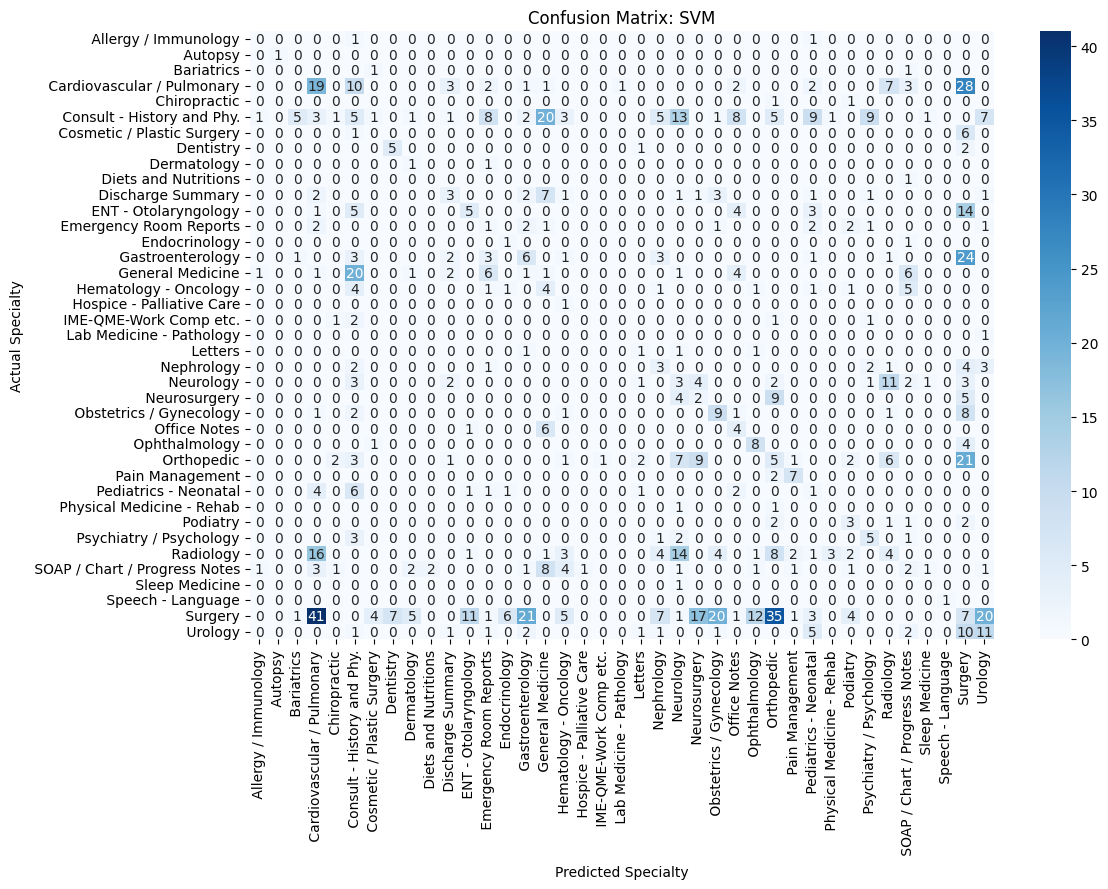

Best model based on macro F1-score: SVM


In [14]:
best_model_name = results_df.loc[
    results_df["F1-Score"].idxmax(), "Model"
]

best_pred = models_predictions[best_model_name]
labels = sorted(y_test.unique())

cm = confusion_matrix(
    y_test,
    best_pred,
    labels=labels
)

plt.figure(figsize=(12, 9))

sns.heatmap(
    cm,
    cmap="Blues",
    annot=True,
    fmt="d",
    xticklabels=labels,
    yticklabels=labels
)

plt.title(f"Confusion Matrix: {best_model_name}")
plt.xlabel("Predicted Specialty")
plt.ylabel("Actual Specialty")
plt.xticks(rotation=90)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

print("Best model based on macro F1-score:", best_model_name)

In [15]:
best_row = results_df.loc[results_df["F1-Score"].idxmax()]

print("BEST ALGORITHM:", best_row["Model"])
print("Accuracy:", round(best_row["Accuracy"], 4))
print("Precision:", round(best_row["Precision"], 4))
print("Recall:", round(best_row["Recall"], 4))
print("F1-Score:", round(best_row["F1-Score"], 4))

BEST ALGORITHM: SVM
Accuracy: 0.1247
Precision: 0.1576
Recall: 0.214
F1-Score: 0.1728


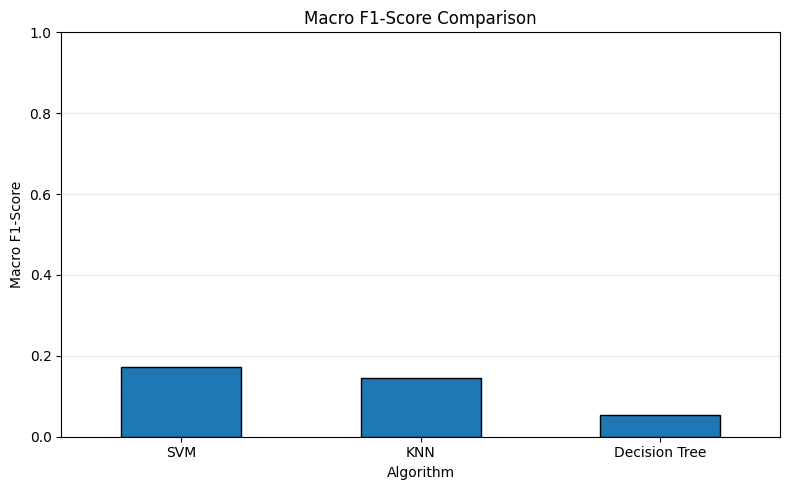

In [21]:
#F1-Score
f1_df = comparison_df["F1-Score"].sort_values(
    ascending=False
)

plt.figure(figsize=(8, 5))
f1_df.plot(kind="bar", edgecolor="black")

plt.title("Macro F1-Score Comparison")
plt.xlabel("Algorithm")
plt.ylabel("Macro F1-Score")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.savefig(
    "medical_f1_comparison.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

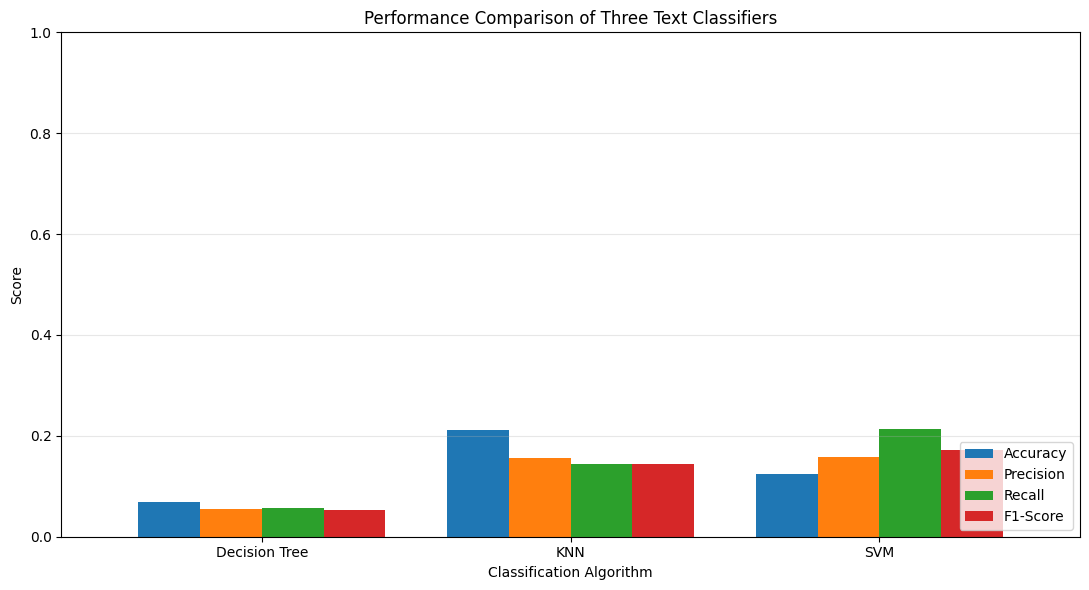

In [22]:
#Performance comparision
# Keep only the three required algorithms
comparison_df = results_df[
    results_df["Model"].isin(["KNN", "Decision Tree", "SVM"])
].copy()

metrics = ["Accuracy", "Precision", "Recall", "F1-Score"]

# Convert metric values to numeric if needed
comparison_df[metrics] = comparison_df[metrics].apply(
    pd.to_numeric, errors="coerce"
)

comparison_df = comparison_df.set_index("Model")
comparison_df = comparison_df.reindex(
    ["Decision Tree", "KNN", "SVM"]
)

ax = comparison_df[metrics].plot(
    kind="bar",
    figsize=(11, 6),
    width=0.8
)

ax.set_title("Performance Comparison of Three Text Classifiers")
ax.set_xlabel("Classification Algorithm")
ax.set_ylabel("Score")
ax.set_ylim(0, 1)
ax.set_xticklabels(ax.get_xticklabels(), rotation=0)
ax.legend(loc="lower right")
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.savefig(
    "medical_algorithm_comparison.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()